<small>(C) Copyright IBM 2026. Licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0); see the `LICENSE` file in the repository root.</small>

# Tutorial 1 — Decoding a qLDPC code on a single GPU

This notebook walks through the full Pelagos workflow on **one GPU**:

1. Decode a toy code, and learn what the decoder returns.
2. Build a decoding problem from a circuit-level noise model: the
   [[72,12,6]] bivariate bicycle code, 6 rounds, physical error rate 0.3%.
3. Sample shots with [stim](https://github.com/quantumlib/Stim), decode them in batches, and measure
   the **logical error rate**.
4. Compare plain min-sum BP with **Relay-BP**.
5. Measure **throughput** as a function of batch size, and see why a few slow shots set the time for a whole batch.
6. Sweep the physical error rate.
7. *(Optional)* Cross-check against the `relay-bp` Rust CPU reference.

**Requirements:** a CUDA or ROCm GPU and the tutorial dependencies:

```bash
pip install "pelagos[tutorials]"          # or, from a clone:  uv sync --extra tutorials
```

**Runtime:** about 3–4 minutes on a laptop GPU (RTX 3000 Ada, 8 GB). The first decode of each
new configuration also includes Triton JIT compilation.

## 0. Setup

In [1]:
import gzip
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import stim
import torch

import pelagos
from pelagos import RelayBPDecoder
from pelagos.stim.sinter.check_matrices import CheckMatrices

assert torch.cuda.is_available(), "Pelagos needs a GPU (CUDA or ROCm); there is no CPU fallback."
DEVICE = "cuda:0"  # PyTorch also uses the "cuda" device type on ROCm builds.

print("GPU:    ", torch.cuda.get_device_name(0))
print("torch:  ", torch.__version__, "| stim:", stim.__version__)
free, total = torch.cuda.mem_get_info()
print(f"memory:  {free / 2**30:.1f} GiB free of {total / 2**30:.1f} GiB")

GPU:     NVIDIA RTX 3000 Ada Generation Laptop GPU
torch:   2.13.0+cu130 | stim: 1.16.0
memory:  7.5 GiB free of 7.6 GiB


## 1. Hello, decoder

A decoder is defined by a **check matrix** $H$ (checks × error mechanisms, sparse CSR) and a
**prior probability** for each error mechanism. Given a syndrome $s$, it returns an error
estimate $\hat e$ with $H\hat e = s \pmod 2$.

Three details are easy to get wrong:

* `algo` is required: `"relay"` or `"plain"`.
* `decode()` takes a **batch** `[B, C]` of `uint8` syndromes as a **torch tensor on the GPU**, not a numpy array.
* The estimated error pattern is stored under `result["errors"]`.

In [2]:
from scipy.sparse import csr_matrix

H_toy = csr_matrix(np.array([[1, 1, 0],
                             [0, 1, 1],
                             [1, 0, 1]], dtype=np.uint8))
priors_toy = np.full(3, 0.05)

toy = RelayBPDecoder(H_csr=H_toy, error_priors=priors_toy, algo="relay",
                     pre_iter=10, num_sets=2, set_max_iter=10, stop_nconv=1)

true_error = np.array([1, 0, 0], dtype=np.uint8)
syndrome = (H_toy @ true_error) % 2                     # -> [1, 0, 1]
batch = torch.from_numpy(syndrome[None, :].astype(np.uint8)).to(DEVICE)   # shape [B=1, C=3]

result = toy.decode(batch)
for key, value in result.items():
    print(f"{key:>20}: {value.cpu().numpy()}")

              errors: [[1 0 0]]
             weights: [2.944439]
          valid_mask: [ True]
          iterations: [1]
         found_count: [1]
 unconverged_indices: []


The fields you will use most:

| key | shape | meaning |
|---|---|---|
| `errors` | `[B, V]` | estimated error pattern $\hat e$ (`uint8`) |
| `found_count` | `[B]` | number of valid solutions found; `> 0` means BP **converged** |
| `iterations` | `[B]` | total BP iterations spent on that shot |
| `weights` | `[B]` | weight (negative log-likelihood) of the returned solution |

## 2. A realistic decoding problem: circuit-level noise

The repository ships stim circuits for bivariate bicycle codes under uniform circuit-level
noise in `tests/testdata/bicycle_bivariate/`. We turn one into a **detector error model (DEM)**,
then into matrices that Pelagos can decode:

* `check_matrix` $H$: detectors × error mechanisms. Column $j$ lists the detectors that error $j$ flips.
* `observables_matrix` $O$: logical observables × error mechanisms.
* `error_priors`: the probability of each error mechanism.

Decoding succeeds when the predicted observable flips $O\hat e$ match the true flips.

In [3]:
def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "tests" / "testdata" / "bicycle_bivariate").is_dir():
            return p
    raise FileNotFoundError("Run this notebook from inside the pelagos repository.")

CIRCUIT_DIR = find_repo_root() / "tests" / "testdata" / "bicycle_bivariate"


def load_circuit(code="72_12_6", error_rate=0.003, basis="memory_X"):
    # The bundled circuits are gzipped; stim.Circuit.from_file does not decompress them.
    [path] = CIRCUIT_DIR.glob(f"*bicycle_bivariate_{code}_{basis},*error_rate={error_rate},*.stim.gz")
    return stim.Circuit(gzip.decompress(path.read_bytes()).decode())


def build_problem(code="72_12_6", error_rate=0.003):
    circuit = load_circuit(code, error_rate)
    dem = circuit.detector_error_model(decompose_errors=False)
    cm = CheckMatrices.from_dem(dem)
    return dem, cm.check_matrix.tocsr(), cm.observables_matrix.tocsr(), cm.error_priors


dem, H, O, priors = build_problem("72_12_6", 0.003)
print(f"check matrix H:        {H.shape[0]} detectors x {H.shape[1]} error mechanisms, {H.nnz} non-zeros")
print(f"observables matrix O:  {O.shape[0]} logical observables")
print(f"error priors:          min {priors.min():.1e}, median {np.median(priors):.1e}, max {priors.max():.1e}")

check matrix H:        432 detectors x 16200 error mechanisms, 91188 non-zeros
observables matrix O:  12 logical observables
error priors:          min 2.0e-04, median 4.0e-04, max 1.1e-02


### Sampling shots

`dem.compile_sampler()` draws random errors from the model and returns, for each shot, the
detector outcomes (the syndrome) and the true observable flips.

In [4]:
NUM_SHOTS = 4096
detectors, observables, _ = dem.compile_sampler(seed=2026).sample(NUM_SHOTS)
syndromes_gpu = torch.from_numpy(detectors.astype(np.uint8)).to(DEVICE)

print("syndromes:", tuple(syndromes_gpu.shape), "| mean syndrome weight:", detectors.sum(1).mean().round(1))
print("fraction of shots with a non-trivial logical flip:", observables.any(1).mean().round(3))

syndromes: (4096, 432) | mean syndrome weight: 43.2
fraction of shots with a non-trivial logical flip: 0.969


### Batched decoding helper

The decoder processes a batch of syndromes in parallel. GPU memory grows with
`batch_size × H.nnz`, so large sample sets are decoded in chunks. Two limits apply:

* **Memory:** on an 8 GB GPU, about 1024 shots fit for this code and about 512 for [[144,12,12]].
* **Indexing:** `H.nnz × batch_size` must stay below $2^{31}$; otherwise the decoder raises an error that tells you the largest safe batch.

In [5]:
def decode_all(decoder, syndromes, batch_size=1024):
    # Decode [N, C] GPU syndromes in chunks and return numpy arrays plus wall time (s).
    errors, found, iters = [], [], []
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for start in range(0, syndromes.shape[0], batch_size):
        out = decoder.decode(syndromes[start:start + batch_size])
        errors.append(out["errors"])
        found.append(out["found_count"])
        iters.append(out["iterations"])
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    return (torch.cat(errors).cpu().numpy().astype(np.uint8),
            torch.cat(found).cpu().numpy(),
            torch.cat(iters).cpu().numpy(),
            elapsed)


def logical_failures(errors, O, observables):
    # A shot fails if any predicted logical flip differs from the true one.
    predicted = ((O @ errors.T) % 2).T.astype(bool)
    return np.any(predicted != observables, axis=1)


def warm_up(decoder, syndromes, batch_size=1024):
    # The first call with a given batch shape triggers Triton JIT compilation and autotuning.
    decoder.decode(syndromes[:batch_size])
    torch.cuda.synchronize()

## 3. Plain BP vs. Relay-BP

**Plain min-sum BP** runs a fixed number of iterations and fails on many shots: qLDPC Tanner
graphs contain short cycles and trapping sets, and BP can oscillate on them without converging.

**Relay-BP** runs a chain of BP *legs* instead:

* `pre_iter` ($T_0$) iterations with ordered memory strength `gamma0`, then
* up to `num_sets` ($R$) relay legs of `set_max_iter` ($T_r$) iterations each. Every leg draws new
  per-variable memory strengths $\gamma_j$ from `gamma_dist_interval` (which may be negative)
  and starts from the previous leg's posterior.
* Decoding stops once `stop_nconv` ($S$) valid solutions are found, and the lowest-weight one is returned.

A larger $S$ gives the decoder more candidates to choose from: accuracy improves, and runtime grows.

In [6]:
configs = {
    "plain BP (200 iters)": dict(algo="plain", pre_iter=200, num_sets=0, stop_nconv=1),
    "Relay-BP, S=1":        dict(algo="relay", pre_iter=80, num_sets=100, set_max_iter=60,
                                 gamma0=0.65, gamma_dist_interval=(-0.24, 0.66), stop_nconv=1),
    "Relay-BP, S=5":        dict(algo="relay", pre_iter=80, num_sets=100, set_max_iter=60,
                                 gamma0=0.65, gamma_dist_interval=(-0.24, 0.66), stop_nconv=5),
}

runs = {}
for name, kwargs in configs.items():
    decoder = RelayBPDecoder(H_csr=H, error_priors=priors, data_type="float32", **kwargs)
    warm_up(decoder, syndromes_gpu)
    errors, found, iters, elapsed = decode_all(decoder, syndromes_gpu)
    fails = logical_failures(errors, O, observables)
    runs[name] = dict(fails=fails, found=found, iters=iters, elapsed=elapsed)

print(f"{'decoder':<22}{'LER':>9}{'±1σ':>9}{'converged':>11}{'mean iters':>12}{'µs/shot':>10}")
for name, r in runs.items():
    ler = r["fails"].mean()
    sigma = np.sqrt(ler * (1 - ler) / NUM_SHOTS)
    print(f"{name:<22}{ler:>9.4f}{sigma:>9.4f}{(r['found'] > 0).mean():>11.3f}"
          f"{r['iters'].mean():>12.0f}{r['elapsed'] / NUM_SHOTS * 1e6:>10.0f}")

decoder                     LER      ±1σ  converged  mean iters   µs/shot
plain BP (200 iters)     0.1963   0.0062      0.666         109      2324
Relay-BP, S=1            0.0190   0.0021      1.000          28      2216
Relay-BP, S=5            0.0088   0.0015      1.000         164      8617


Plain BP fails to converge on a large fraction of shots, and most of those become logical
errors. Relay-BP converges on nearly every shot and lowers the logical error rate by an order of
magnitude. Collecting more solutions (`S=5`) lowers it again, at several times the cost.

(These are *per-shot* logical error rates over all 12 logical qubits and all 6 rounds.)

## 4. Where does the time go? Iteration counts per shot

Most shots converge within the first few dozen iterations. A small tail needs many relay legs.

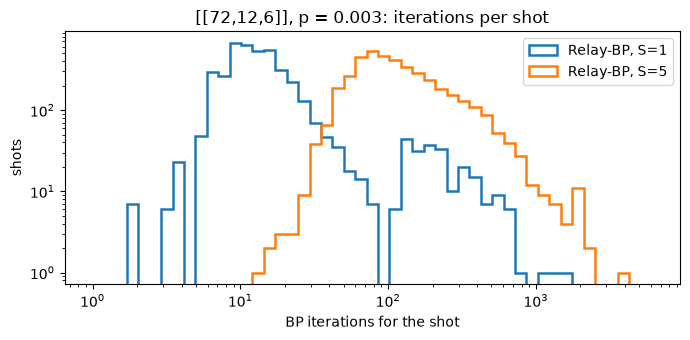

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.logspace(0, np.log10(6100), 50)
for name in ["Relay-BP, S=1", "Relay-BP, S=5"]:
    ax.hist(runs[name]["iters"], bins=bins, histtype="step", linewidth=1.8, label=name)
ax.set(xscale="log", yscale="log", xlabel="BP iterations for the shot", ylabel="shots",
       title="[[72,12,6]], p = 0.003: iterations per shot")
ax.legend()
plt.tight_layout()
plt.show()

The GPU decodes a batch in lock-step, so the batch finishes when its **slowest** shot finishes.
Converged lanes are compacted out of the work, which is why a heavy tail does not multiply the
cost by the batch size. It still sets a floor on how long each batch takes.

## 5. Throughput vs. batch size

Larger batches amortize kernel-launch overhead and keep more of the GPU busy. We time the same
2048 shots at several batch sizes. Each batch size is warmed up first, so that JIT compilation
is not counted.

batch    16:      188 shots/s   (5333 µs/shot)


batch    64:      320 shots/s   (3121 µs/shot)


batch   256:      372 shots/s   (2690 µs/shot)


batch  1024:      395 shots/s   (2532 µs/shot)


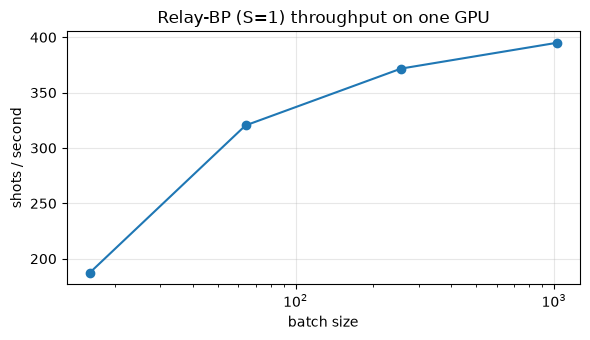

In [8]:
relay = RelayBPDecoder(H_csr=H, error_priors=priors, **configs["Relay-BP, S=1"])
subset = syndromes_gpu[:2048]
batch_sizes = [16, 64, 256, 1024]

throughput = []
for bs in batch_sizes:
    warm_up(relay, subset, bs)
    *_, elapsed = decode_all(relay, subset, batch_size=bs)
    throughput.append(subset.shape[0] / elapsed)
    print(f"batch {bs:>5}: {throughput[-1]:>8.0f} shots/s   ({elapsed / subset.shape[0] * 1e6:.0f} µs/shot)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(batch_sizes, throughput, "o-")
ax.set(xscale="log", xlabel="batch size", ylabel="shots / second",
       title="Relay-BP (S=1) throughput on one GPU")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Logical error rate vs. physical error rate

The repository ships each circuit at $p \in \{0.002, 0.003, 0.005\}$. We rebuild the decoding
problem for each value and measure the logical error rate with Relay-BP (S=1).

p = 0.002:  LER = 0.0034 ± 0.0009   (4.3 s incl. JIT)


p = 0.003:  LER = 0.0203 ± 0.0022   (9.6 s incl. JIT)


p = 0.005:  LER = 0.1130 ± 0.0049   (74.3 s incl. JIT)


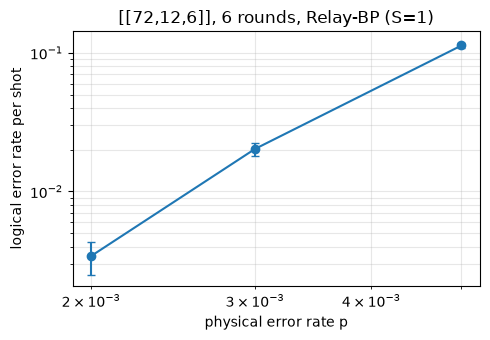

In [9]:
error_rates = [0.002, 0.003, 0.005]
lers, sigmas = [], []
for p in error_rates:
    dem_p, H_p, O_p, priors_p = build_problem("72_12_6", p)
    det_p, obs_p, _ = dem_p.compile_sampler(seed=7).sample(NUM_SHOTS)
    dec_p = RelayBPDecoder(H_csr=H_p, error_priors=priors_p, **configs["Relay-BP, S=1"])
    errors_p, *_ , elapsed = decode_all(dec_p, torch.from_numpy(det_p.astype(np.uint8)).to(DEVICE))
    ler = logical_failures(errors_p, O_p, obs_p).mean()
    lers.append(ler)
    sigmas.append(np.sqrt(ler * (1 - ler) / NUM_SHOTS))
    print(f"p = {p:.3f}:  LER = {ler:.4f} ± {sigmas[-1]:.4f}   ({elapsed:.1f} s incl. JIT)")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.errorbar(error_rates, lers, yerr=sigmas, fmt="o-", capsize=3)
ax.set(xscale="log", yscale="log", xlabel="physical error rate p", ylabel="logical error rate per shot",
       title="[[72,12,6]], 6 rounds, Relay-BP (S=1)")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

With 4096 shots, rates below about $10^{-3}$ come with wide error bars. For publication-quality
curves, sample more shots. The benchmark CLI (below) keeps sampling until it reaches
`--target-errors` logical errors (or `--max-shots`).

## 7. (Optional) Cross-check against the Rust CPU reference

Pelagos follows the algorithm of the [`relay-bp`](https://pypi.org/project/relay-bp/) Rust
package, and its test suite checks agreement bit for bit on small codes
(`tests/test_triton_against_rust.py`). Here we run both decoders with the same parameters on
the same shots. Their random number streams differ, so individual decodings can differ.
The logical error rates should agree within statistical error. Install the reference with
`pip install "pelagos[rust]"`.

In [10]:
try:
    import relay_bp
except ImportError:
    relay_bp = None
    print("relay-bp not installed; skipping (pip install 'pelagos[rust]').")

if relay_bp is not None:
    n = 512
    p = configs["Relay-BP, S=1"]
    rust = relay_bp.RelayDecoderF32(
        H, error_priors=priors, gamma0=p["gamma0"], pre_iter=p["pre_iter"], num_sets=p["num_sets"],
        set_max_iter=p["set_max_iter"], gamma_dist_interval=p["gamma_dist_interval"],
        stop_nconv=p["stop_nconv"], seed=1234,
    )
    t0 = time.perf_counter()
    rust_errors = np.asarray(rust.decode_batch(detectors[:n].astype(np.uint8)), dtype=np.uint8)
    rust_time = time.perf_counter() - t0

    warm_up(relay, syndromes_gpu, n)   # exclude JIT compilation for this batch shape
    gpu_errors, *_, gpu_time = decode_all(relay, syndromes_gpu[:n], batch_size=n)

    for name, e, t in [("Rust (CPU)", rust_errors, rust_time), ("Pelagos (GPU)", gpu_errors, gpu_time)]:
        valid = np.all(((H @ e.T) % 2).T == detectors[:n], axis=1).mean()
        ler = logical_failures(e, O, observables[:n]).mean()
        print(f"{name:<14} LER = {ler:.4f}   syndrome satisfied: {valid:.3f}   {t / n * 1e3:6.2f} ms/shot")

Rust (CPU)     LER = 0.0273   syndrome satisfied: 1.000    12.44 ms/shot
Pelagos (GPU)  LER = 0.0234   syndrome satisfied: 1.000     2.88 ms/shot


## Next steps

* **Larger codes.** Replace `"72_12_6"` with `"144_12_12"` (the gross code) or `"288_12_18"`.
  Their check matrices are much larger ([[144,12,12]] has about 4× the non-zeros of [[72,12,6]]),
  so lower `batch_size` to fit in memory.
* **Precision.** Pass `data_type="float16"` to halve memory traffic, or `"float64"` for reference-grade numerics.
* **Benchmark CLI.** `pelagos_benchmark.py` automates everything above (sampling, batching,
  timing, statistics) and adds per-basis detector filtering:

  ```bash
  python pelagos_benchmark.py --backend triton \
      --circuit bicycle_bivariate_144_12_12_memory_X --basis x \
      --distance 12 --rounds 12 --error-rate 0.003 --data-type float32
  ```

  Run it again with `--backend rust` to compare against the CPU reference.